# License Plate Recognition (OpenCV + pytesseract)

Course project on classical CV + OCR. The pipeline:

1. Load real car photos with labeled plate boxes.
2. Use OpenCV to find the plate region, with a Haar cascade and with a contour + aspect-ratio heuristic, and score both against the labeled boxes.
3. Crop plates, clean them up, and run pytesseract on them.

Data: the Roboflow "Vehicle Registration Plates" dataset (CC BY 4.0, 8,823 images annotated in COCO format), loaded from the `keremberke/license-plate-object-detection` parquet on Hugging Face. I use the 882-image test split. The photos come from many countries, so plate formats and fonts vary a lot. The dataset has boxes but no plate text, so detection gets a real score and OCR only gets examples.

The companion notebook (96) does character recognition with a tiny CNN instead of OCR.

**Heads up on pytesseract:** it depends on the Tesseract OCR binary being on the system. If it isn't installed, the OCR step will fail with `TesseractNotFoundError` and the rest of the notebook still demonstrates plate-region detection.

In [1]:
# !pip install opencv-python-headless pytesseract pillow -q
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont

try:
    import pytesseract
    HAS_TESSERACT = True
except Exception:
    HAS_TESSERACT = False

DATA_DIR = Path("../../data/plates")
DATA_DIR.mkdir(parents=True, exist_ok=True)
print(f"data dir: {DATA_DIR}")


data dir: ../../data/plates


## Load real plate photos

882 test images, 902 labeled plates


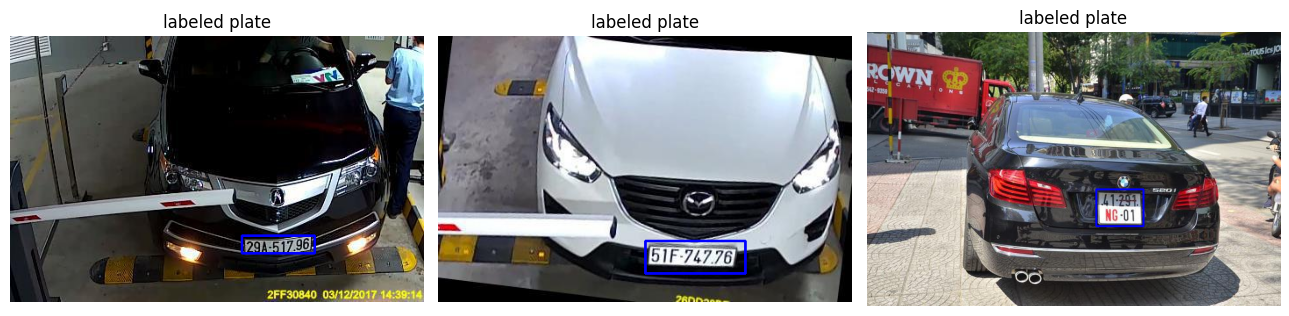

In [2]:
import io
import pandas as pd
PQ = DATA_DIR / "plates_test.parquet"
if not PQ.exists():
    pd.read_parquet("https://huggingface.co/datasets/keremberke/license-plate-object-detection/resolve/"
                    "refs%2Fconvert%2Fparquet/full/test/0000.parquet").to_parquet(PQ)
plates = pd.read_parquet(PQ)
samples = []
for _, r in plates.iterrows():
    img = cv2.imdecode(np.frombuffer(r["image"]["bytes"], np.uint8), cv2.IMREAD_COLOR)
    samples.append({"img": img, "boxes": [tuple(map(int, b)) for b in r["objects"]["bbox"]]})  # COCO x, y, w, h
print(f"{len(samples)} test images, {sum(len(s['boxes']) for s in samples)} labeled plates")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, s in zip(axes, samples[:3]):
    vis = s["img"].copy()
    for (x, y, w, h) in s["boxes"]:
        cv2.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 2)
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax.axis("off"); ax.set_title("labeled plate")
plt.tight_layout(); plt.show()

## Plate detection

Two classical detectors: the Haar cascade for Russian plates that ships with OpenCV, and a contour heuristic (threshold, find rectangular contours, keep those with plate-like aspect ratios). I score each against the labeled boxes: a labeled plate counts as found if any of the detector's top-5 candidates overlaps it with IoU of at least 0.3.

haar     plates found: 310/902 (34.4%)   candidates per image: 0.4
contour  plates found: 391/902 (43.3%)   candidates per image: 2.8


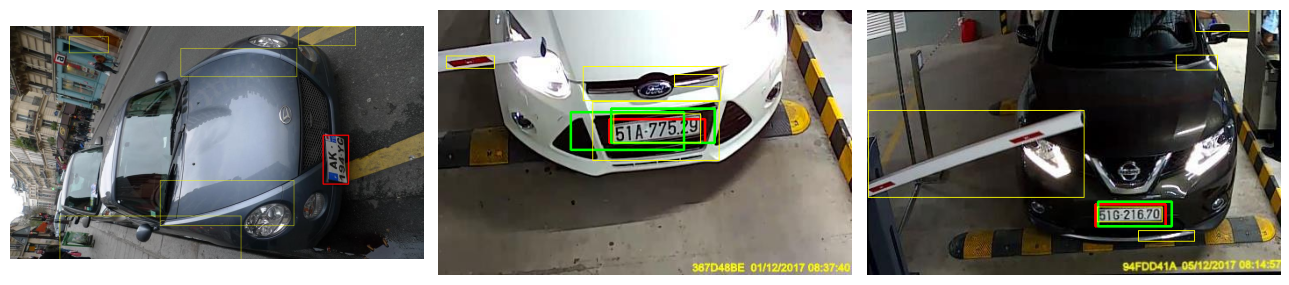

In [3]:
def haar_plate_boxes(gray_img):
    cascade_path = cv2.data.haarcascades + "haarcascade_russian_plate_number.xml"
    if not os.path.exists(cascade_path):
        return []
    cascade = cv2.CascadeClassifier(cascade_path)
    boxes = cascade.detectMultiScale(gray_img, scaleFactor=1.1, minNeighbors=5)
    return [tuple(map(int, b)) for b in boxes][:5]

def contour_plate_boxes(gray_img):
    # threshold + contour, filter by aspect ratio + relative area
    _, bw = cv2.threshold(gray_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(bw, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    H, W = gray_img.shape
    candidates = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        ar = w / max(h, 1)
        area_frac = (w * h) / (H * W)
        # plate-ish: wide aspect, not the whole image, not microscopic
        if 2.0 < ar < 6.0 and 0.002 < area_frac < 0.25:
            candidates.append((x, y, w, h))
    # sort by area desc and return top few
    candidates.sort(key=lambda b: b[2] * b[3], reverse=True)
    return candidates[:5]

def iou(a, b):
    ax, ay, aw, ah = a; bx, by, bw, bh = b
    ix = max(0, min(ax + aw, bx + bw) - max(ax, bx)); iy = max(0, min(ay + ah, by + bh) - max(ay, by))
    inter = ix * iy
    return inter / (aw * ah + bw * bh - inter + 1e-9)

found = {"haar": 0, "contour": 0}
n_cand = {"haar": 0, "contour": 0}
total = 0
for s in samples:
    gray = cv2.cvtColor(s["img"], cv2.COLOR_BGR2GRAY)
    s["pred"] = {"haar": haar_plate_boxes(gray), "contour": contour_plate_boxes(gray)}
    for m in found:
        n_cand[m] += len(s["pred"][m])
        found[m] += sum(any(iou(g, p) >= 0.3 for p in s["pred"][m]) for g in s["boxes"])
    total += len(s["boxes"])
for m in found:
    print(f"{m:8s} plates found: {found[m]}/{total} ({found[m] / total:.1%})   candidates per image: {n_cand[m] / len(samples):.1f}")

# show both detectors on a few images (green = haar, yellow = contour, red = label)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, s in zip(axes, samples[3:6]):
    vis = s["img"].copy()
    for (x, y, w, h) in s["boxes"]: cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 0, 255), 2)
    for (x, y, w, h) in s["pred"]["haar"]: cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
    for (x, y, w, h) in s["pred"]["contour"]: cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 255), 1)
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax.axis("off")
plt.tight_layout(); plt.show()

## OCR on labeled plate crops

To look at the OCR step on its own, I crop the *labeled* plate boxes (so detection errors don't get in the way), upscale, threshold, and run tesseract on a few of them. There is no ground-truth text in this dataset, so this is a visual check, not a score.

plate 83x20px -> OCR ''
plate 114x37px -> OCR '51F71776'
plate 73x57px -> OCR ''


plate 63x121px -> OCR ''
plate 109x27px -> OCR '151A-775239'


plate 80x25px -> OCR '516-21670'


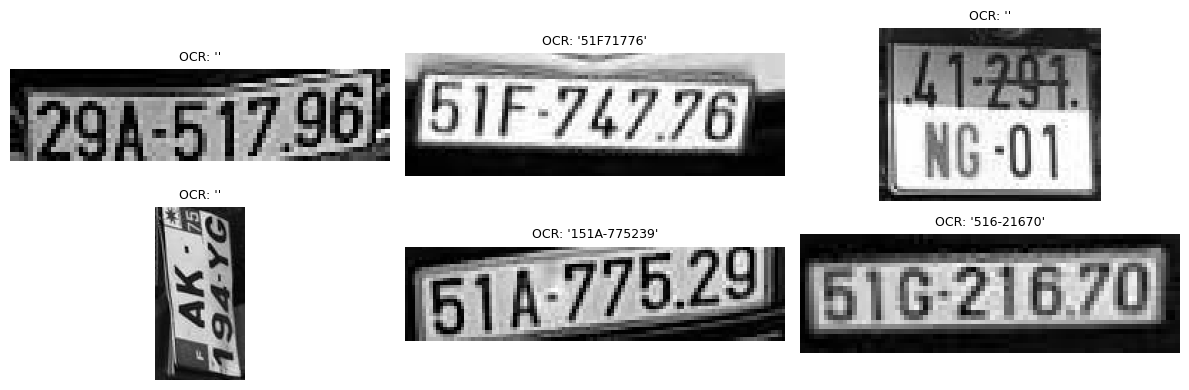

In [4]:
config = "--psm 7 -c tessedit_char_whitelist=ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789-"
picks = [s for s in samples if s["boxes"] and s["boxes"][0][2] >= 60][:6]   # plates at least 60 px wide
fig, axes = plt.subplots(2, 3, figsize=(12, 4))
for ax, s in zip(axes.flat, picks):
    x, y, w, h = s["boxes"][0]
    crop = cv2.cvtColor(s["img"][y:y + h, x:x + w], cv2.COLOR_BGR2GRAY)
    # upscale + threshold helps tesseract a lot on small crops
    crop_big = cv2.resize(crop, None, fx=2.0, fy=2.0, interpolation=cv2.INTER_CUBIC)
    _, crop_bin = cv2.threshold(crop_big, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    text = ""
    if HAS_TESSERACT:
        try:
            text = pytesseract.image_to_string(crop_bin, config=config).strip().replace(" ", "")
        except Exception as e:
            text = f"(tesseract failed: {e})"
    ax.imshow(crop, cmap="gray"); ax.axis("off"); ax.set_title(f"OCR: '{text}'", fontsize=9)
    print(f"plate {w}x{h}px -> OCR '{text}'")
plt.tight_layout(); plt.show()

## What I learned writing this

- On 902 labeled plates in 882 real photos, neither classical detector is good. The Haar cascade finds 34.4% of plates and the contour heuristic 43.3%, and the contour method needs about 2.8 candidate boxes per image to get there, so most of its boxes are false alarms (windows, grilles, signs). The Haar cascade was trained on Russian plates and this set has plates from many countries.
- OCR is the weaker step. On six clean, labeled crops, tesseract returned nothing for three of them, and on the other three it got close but not right. For example, I read the second crop as "51F-747.76" by eye and tesseract returned "51F71776". Many plates in this set (the ones in the figure look Vietnamese) use a "." that my character whitelist doesn't allow, and two-row or rotated plates break the single-line `--psm 7` mode completely.
- Upscaling 2x + Otsu thresholding is still worth doing on small crops, but it can't fix the layout problems above.
- If I were building this for real, I'd skip Haar + contour entirely and use a small detection model (YOLOv8n fine-tuned on this plate dataset), then a recognizer trained on real plate crops instead of tesseract. The classical pipeline is here mostly because that's what the course asked for.